In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import seaborn as sns
import importlib
import bcifswsni_bn
importlib.reload(bcifswsni_bn)

from bcifswsni_bn import run_model
import nibabel as nib


In [3]:
img = nib.load('brain.mnc')
data = img.get_fdata()

print(data.shape)

(181, 217, 181)


In [4]:
slice_img = data[:, :, 90]

(np.float64(-0.5), np.float64(216.5), np.float64(180.5), np.float64(-0.5))

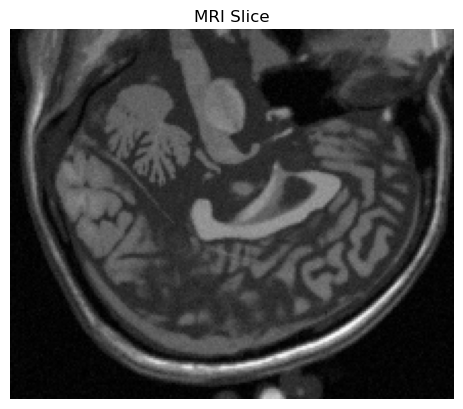

In [5]:
import matplotlib.pyplot as plt

plt.imshow(slice_img, cmap='gray')
plt.title("MRI Slice")
plt.axis('off')

In [6]:
import numpy as np

slice_img = (slice_img - np.min(slice_img)) / (np.max(slice_img) - np.min(slice_img))

In [7]:
slice_img[slice_img < 0.05] = 0

(np.float64(-0.5), np.float64(216.5), np.float64(180.5), np.float64(-0.5))

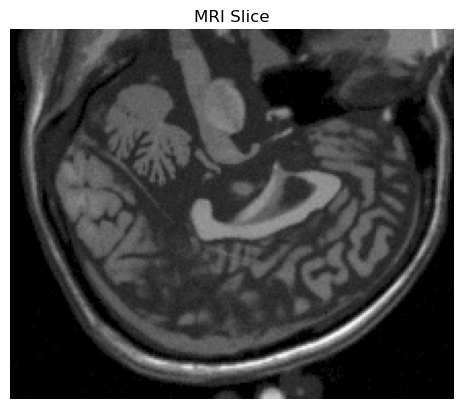

In [8]:
plt.imshow(slice_img, cmap='gray')
plt.title("MRI Slice")
plt.axis('off')

In [9]:
X = slice_img.reshape(-1, 1)

In [10]:
gt = nib.load('ground_truth.mnc').get_fdata()
gt_slice = gt[:, :, 90]

FileNotFoundError: No such file or no access: 'ground_truth.mnc'

In [11]:
def add_gaussian(img, sigma=0.05):
    noise = np.random.normal(0, sigma, img.shape)
    return np.clip(img + noise, 0, 1)

In [12]:
def add_bias_field(img):
    x = np.linspace(0, 1, img.shape[1])
    bias = np.tile(x, (img.shape[0], 1))
    return np.clip(img + 0.3 * bias, 0, 1)